# Level 2 — Task 3: Geographic Analysis

### Mapping Restaurant Locations & Finding Clusters

This dataset contains 9,551 restaurant listings scraped from a Zomato-style
platform, covering cuisine type, cost, ratings, and location across multiple
cities and countries.

**Business question:** Where are restaurants located, and are they spread
evenly or concentrated in specific areas? This shows where competition and
demand are densest.

**Objectives:**
1. Plot the locations of restaurants on a map using longitude and latitude.
2. Identify patterns or clusters of restaurants in specific areas.

## 1. Dataset Overview

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.cluster import DBSCAN

### Note: filename has a trailing space as saved in the data folder

In [2]:
df = pd.read_csv("../../data/Dataset .csv")
df.head()

,Restaurant ID,Restaurant Name,Country Code,City,Address,Locality,Locality Verbose,Longitude,Latitude,Cuisines,...,Currency,Has Table booking,Has Online delivery,Is delivering now,Switch to order menu,Price range,Aggregate rating,Rating color,Rating text,Votes
0,6317637,Le Petit Souffle,162,Makati City,"Third Floor, Century City Mall, Kalayaan Avenu...","Century City Mall, Poblacion, Makati City","Century City Mall, Poblacion, Makati City, Mak...",121.027535,14.565443,"French, Japanese, Desserts",...,Botswana Pula(P),Yes,No,No,No,3,4.8,Dark Green,Excellent,314
1,6304287,Izakaya Kikufuji,162,Makati City,"Little Tokyo, 2277 Chino Roces Avenue, Legaspi...","Little Tokyo, Legaspi Village, Makati City","Little Tokyo, Legaspi Village, Makati City, Ma...",121.014101,14.553708,Japanese,...,Botswana Pula(P),Yes,No,No,No,3,4.5,Dark Green,Excellent,591
2,6300002,Heat - Edsa Shangri-La,162,Mandaluyong City,"Edsa Shangri-La, 1 Garden Way, Ortigas, Mandal...","Edsa Shangri-La, Ortigas, Mandaluyong City","Edsa Shangri-La, Ortigas, Mandaluyong City, Ma...",121.056831,14.581404,"Seafood, Asian, Filipino, Indian",...,Botswana Pula(P),Yes,No,No,No,4,4.4,Green,Very Good,270
3,6318506,Ooma,162,Mandaluyong City,"Third Floor, Mega Fashion Hall, SM Megamall, O...","SM Megamall, Ortigas, Mandaluyong City","SM Megamall, Ortigas, Mandaluyong City, Mandal...",121.056475,14.585318,"Japanese, Sushi",...,Botswana Pula(P),No,No,No,No,4,4.9,Dark Green,Excellent,365
4,6314302,Sambo Kojin,162,Mandaluyong City,"Third Floor, Mega Atrium, SM Megamall, Ortigas...","SM Megamall, Ortigas, Mandaluyong City","SM Megamall, Ortigas, Mandaluyong City, Mandal...",121.057508,14.584450,"Japanese, Korean",...,Botswana Pula(P),Yes,No,No,No,4,4.8,Dark Green,Excellent,229


In [3]:
df.shape

(9551, 21)

## 2. Data Quality Assessment

In [4]:
print("Missing Longitude values:", df["Longitude"].isna().sum())
print("Missing Latitude values:", df["Latitude"].isna().sum())

zero_coords = (df["Longitude"] == 0) | (df["Latitude"] == 0)
print(f"Restaurants with a longitude or latitude of 0: {zero_coords.sum()} ({zero_coords.mean() * 100:.2f}%)")

df[zero_coords]["City"].value_counts().head(5)

Missing Longitude values: 0
Missing Latitude values: 0
Restaurants with a longitude or latitude of 0: 499 (5.22%)


City
New Delhi    233
Noida         94
Gurgaon       48
Faridabad     22
Vadodara      10
Name: count, dtype: int64

No coordinate is missing, but **499 restaurants (5.22%) have a longitude or
latitude of exactly 0**. That is a placeholder for "unknown", not a real
location (it would put them in the ocean off Africa), so plotting them would be
wrong. They are removed from the map analysis.

A second check looks for restaurants located far away from their own city.

In [5]:
geo = df[~zero_coords].copy()

city_median_lat = geo.groupby("City")["Latitude"].transform("median")
city_median_lon = geo.groupby("City")["Longitude"].transform("median")
far = ((geo["Latitude"] - city_median_lat).abs() > 5) | ((geo["Longitude"] - city_median_lon).abs() > 5)

print("Records located far away from their own city:", far.sum())
geo[far][["Restaurant Name", "City", "Longitude", "Latitude"]]

Records located far away from their own city: 1


,Restaurant Name,City,Longitude,Latitude
3513,Test Restaruants for Medio,New Delhi,34.0,35.0


One record is a **test entry** ("Test Restaruants for Medio", listed under New
Delhi) placed at longitude 34, latitude 35, thousands of kilometres from Delhi.
It is clearly invalid and is removed too.

In [6]:
geo = geo[~far].copy()

print("Restaurants with valid coordinates:", len(geo), f"({len(geo) / len(df) * 100:.2f}% of all listings)")
print("Latitude range: ", geo["Latitude"].min(), "to", geo["Latitude"].max())
print("Longitude range:", geo["Longitude"].min(), "to", geo["Longitude"].max())
print("Restaurants sharing exact coordinates with another one:", geo.duplicated(["Longitude", "Latitude"], keep=False).sum())

Restaurants with valid coordinates: 9051 (94.76% of all listings)
Latitude range:  -41.330428 to 55.97698
Longitude range: -157.948486 to 174.8320893
Restaurants sharing exact coordinates with another one: 578


Some restaurants share identical coordinates (for example, several in the same
mall), so points overlap on a map. Semi-transparent markers are used in the
charts so overlapping points show up as darker areas.

## 3. Where Are the Restaurants? (Map Plots)

The dataset only has a `Country Code`, so countries are named using the codes
(checked against each code's coordinates and currency).

In [7]:
country_names = {
    1: "India", 14: "Australia", 30: "Brazil", 37: "Canada", 94: "Indonesia",
    148: "New Zealand", 162: "Philippines", 166: "Qatar", 184: "Singapore",
    189: "South Africa", 191: "Sri Lanka", 208: "Turkey", 214: "UAE",
    215: "United Kingdom", 216: "United States",
}
geo["Country"] = geo["Country Code"].map(country_names)
print("Unmapped country codes:", geo["Country"].isna().sum())

country_counts = geo["Country"].value_counts()
country_table = pd.DataFrame({
    "Country": country_counts.index,
    "Restaurants": country_counts.values,
    "Percentage": (country_counts.values / len(geo) * 100).round(2),
})
country_table

Unmapped country codes: 0


,Country,Restaurants,Percentage
0,India,8155,90.10
1,United States,434,4.80
2,United Kingdom,80,0.88
3,Brazil,60,0.66
4,South Africa,60,0.66
5,UAE,60,0.66
6,New Zealand,39,0.43
7,Turkey,34,0.38
8,Australia,24,0.27
9,Philippines,22,0.24


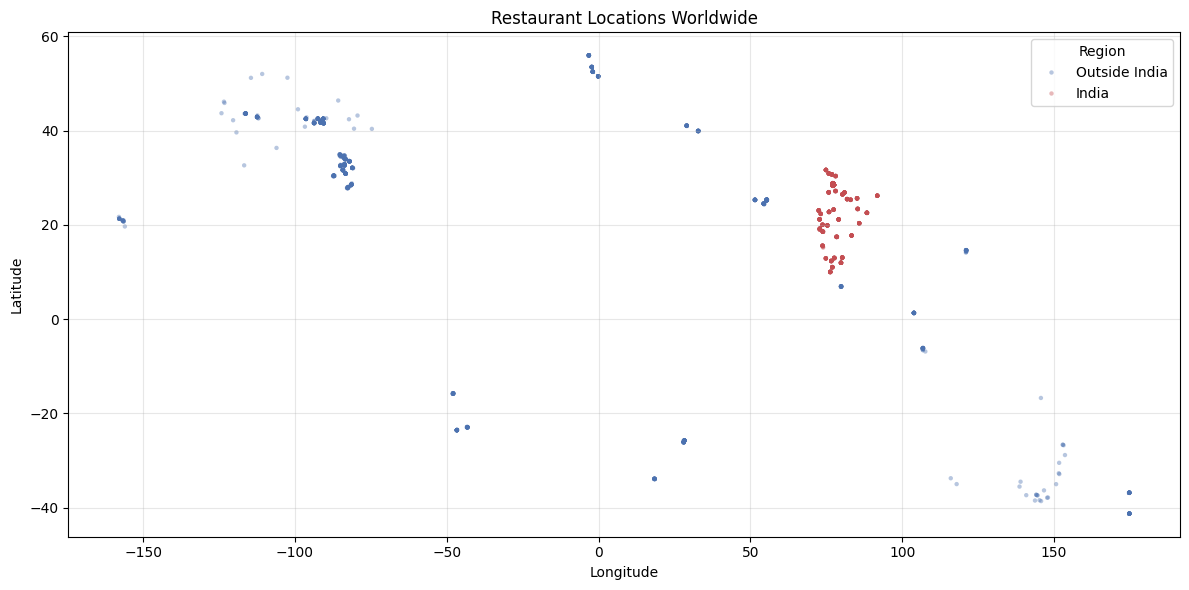

In [8]:
geo["Region"] = np.where(geo["Country"] == "India", "India", "Outside India")

plt.figure(figsize=(12, 6))
sns.scatterplot(
    data=geo, x="Longitude", y="Latitude", hue="Region",
    s=10, alpha=0.4, linewidth=0,
    palette={"India": "#C44E52", "Outside India": "#4C72B0"},
)
plt.title("Restaurant Locations Worldwide")
plt.xlabel("Longitude")
plt.ylabel("Latitude")
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

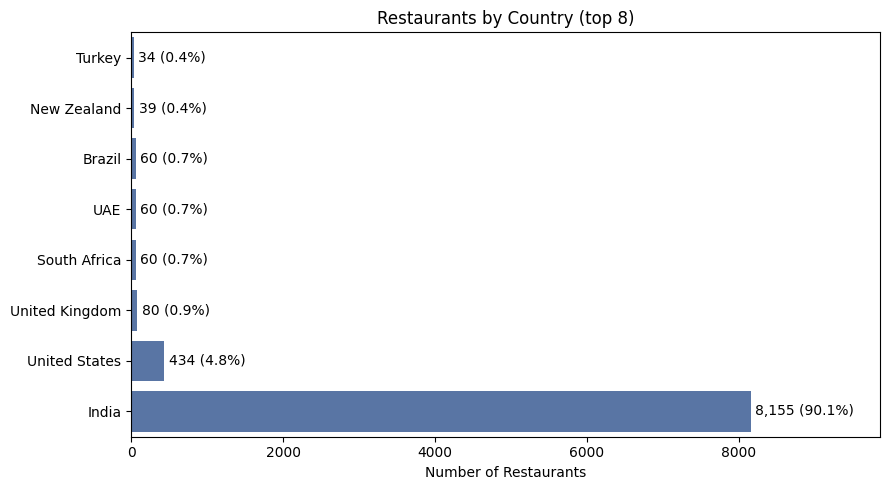

In [9]:
top_c = country_table.head(8).sort_values("Restaurants")

plt.figure(figsize=(9, 5))
ax = sns.barplot(x=top_c["Restaurants"], y=top_c["Country"], color="#4C72B0")
for i, (v, p) in enumerate(zip(top_c["Restaurants"], top_c["Percentage"])):
    ax.text(v + 60, i, f"{v:,} ({p:.1f}%)", va="center")
plt.xlim(0, top_c["Restaurants"].max() + 1700)
plt.title("Restaurants by Country (top 8)")
plt.xlabel("Number of Restaurants")
plt.ylabel("")
plt.tight_layout()
plt.show()

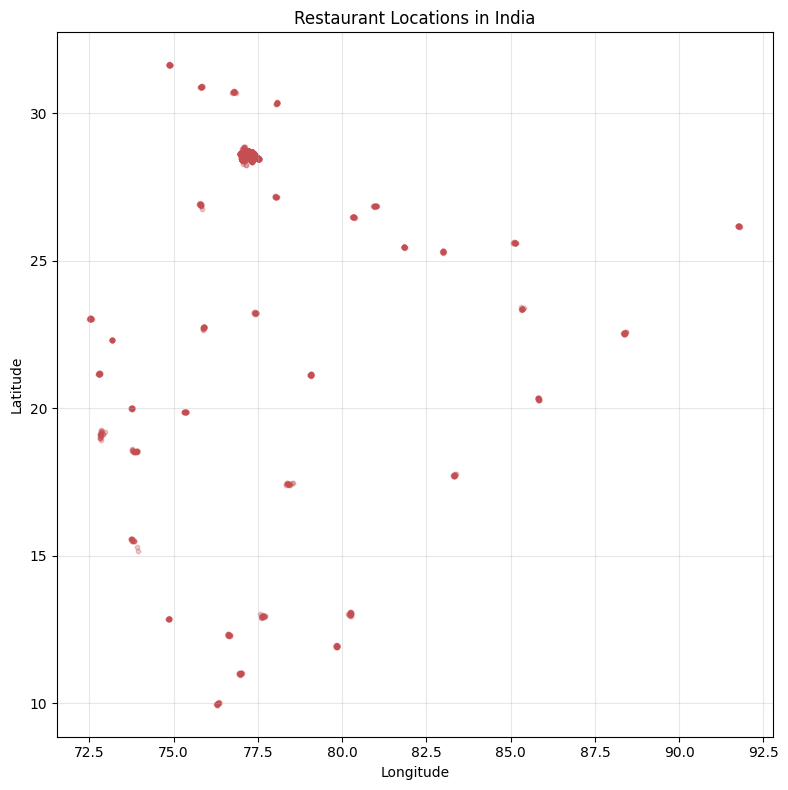

In [10]:
india = geo[geo["Country"] == "India"]

plt.figure(figsize=(8, 8))
plt.scatter(india["Longitude"], india["Latitude"], s=10, alpha=0.3, color="#C44E52")
plt.title("Restaurant Locations in India")
plt.xlabel("Longitude")
plt.ylabel("Latitude")
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

## 4. Clusters Across the Whole Dataset

**DBSCAN** is used to find clusters: it groups restaurants that are close to
each other and marks isolated ones as "noise". Distances are measured in real
kilometres (haversine distance). A cluster needs at least 20 restaurants, each
within 10 km of another.

In [11]:
EPS_KM, MIN_SAMPLES = 10, 20

coords_rad = np.radians(geo[["Latitude", "Longitude"]].values)
db = DBSCAN(eps=EPS_KM / 6371.0, min_samples=MIN_SAMPLES, metric="haversine", algorithm="ball_tree")
geo["Cluster"] = db.fit_predict(coords_rad)

n_clusters = geo.loc[geo["Cluster"] >= 0, "Cluster"].nunique()
n_noise = (geo["Cluster"] == -1).sum()
print(f"Clusters found: {n_clusters}")
print(f"Restaurants not in any cluster (noise): {n_noise} ({n_noise / len(geo) * 100:.2f}%)")

Clusters found: 26
Restaurants not in any cluster (noise): 1013 (11.19%)


In [12]:
clusters = (
    geo[geo["Cluster"] >= 0].groupby("Cluster")
    .agg(Restaurants=("City", "size"),
         Main_City=("City", lambda s: s.mode()[0]),
         Cities_Covered=("City", "nunique"),
         Avg_Latitude=("Latitude", "mean"),
         Avg_Longitude=("Longitude", "mean"))
    .sort_values("Restaurants", ascending=False)
    .round(2)
)
clusters["% of Valid Restaurants"] = (clusters["Restaurants"] / len(geo) * 100).round(2)
clusters.head(8)

,Restaurants,Main_City,Cities_Covered,Avg_Latitude,Avg_Longitude,% of Valid Restaurants
Cluster,,,,,,
12,7483,New Delhi,5,28.58,77.20,82.68
16,59,Noida,1,28.47,77.52,0.65
6,35,Sharjah,2,25.28,55.35,0.39
7,21,Ahmedabad,1,23.04,72.53,0.23
1,20,Davenport,1,41.56,-90.54,0.22
0,20,Athens,1,33.95,-83.38,0.22
5,20,Waterloo,1,42.51,-92.41,0.22
4,20,Valdosta,1,30.85,-83.30,0.22


In [13]:
print(clusters["Restaurants"].describe().round(1))
print("Clusters with 25 restaurants or fewer:", (clusters["Restaurants"] <= 25).sum())

city_sizes = df["City"].value_counts()
print(f"Cities with 20 or fewer listings: {(city_sizes <= 20).sum()} of {len(city_sizes)}")

count      26.0
mean      309.2
std      1463.2
min        20.0
25%        20.0
50%        20.0
75%        20.0
max      7483.0
Name: Restaurants, dtype: float64
Clusters with 25 restaurants or fewer: 23
Cities with 20 or fewer listings: 131 of 141


One huge cluster (Delhi NCR) holds about 83% of the mapped restaurants, and it merges
five cities (New Delhi, Gurgaon, Noida, Faridabad and Ghaziabad) into one
continuous urban area. Almost every other cluster has only 20 restaurants,
which is exactly the minimum. Most cities outside the NCR have about 20
listings, which looks like a limit on how the data was collected, so those
small clusters reflect the dataset and not real restaurant density.

The interesting patterns are therefore **inside** Delhi NCR.

## 5. Zooming into Delhi NCR

In [14]:
ncr = geo[geo["Latitude"].between(28.2, 29.0) & geo["Longitude"].between(76.8, 77.7)].copy()

print(f"Restaurants in the Delhi NCR area: {len(ncr):,} "
      f"({len(ncr) / len(geo) * 100:.2f}% of valid, {len(ncr) / len(df) * 100:.2f}% of all listings)")
ncr["City"].value_counts()

Restaurants in the Delhi NCR area: 7,549 (83.41% of valid, 79.04% of all listings)


City
New Delhi    5239
Gurgaon      1070
Noida         986
Faridabad     229
Ghaziabad      25
Name: count, dtype: int64

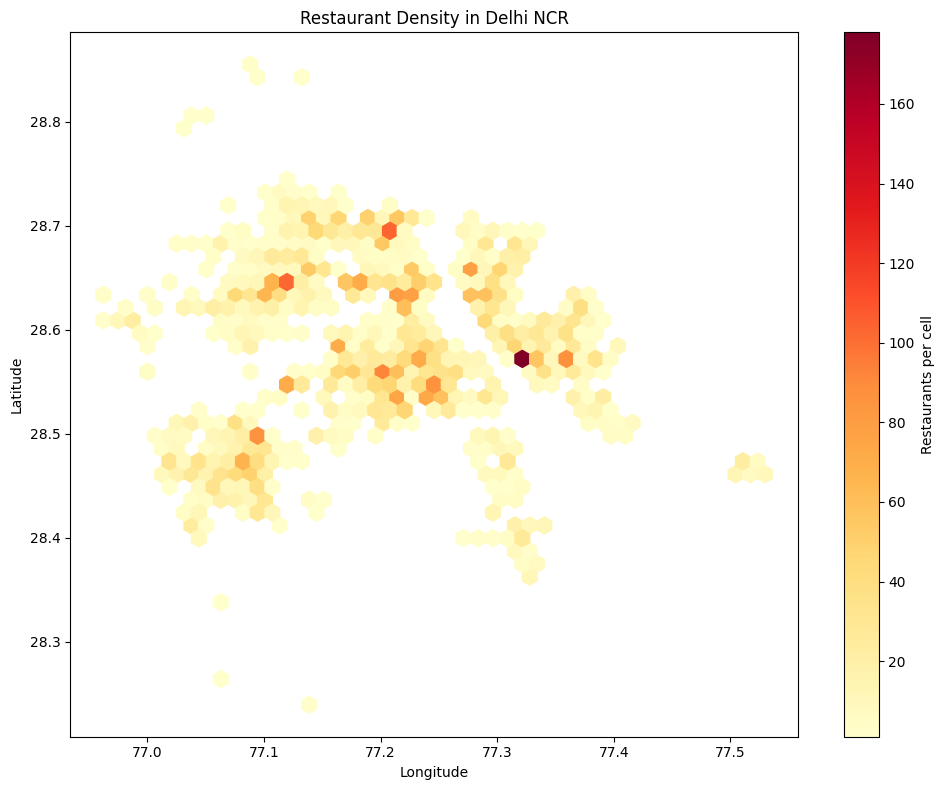

In [15]:
plt.figure(figsize=(10, 8))
hb = plt.hexbin(ncr["Longitude"], ncr["Latitude"], gridsize=45, cmap="YlOrRd", mincnt=1)
plt.colorbar(hb, label="Restaurants per cell")
plt.title("Restaurant Density in Delhi NCR")
plt.xlabel("Longitude")
plt.ylabel("Latitude")
plt.tight_layout()
plt.show()

DBSCAN is run again, this time on the NCR only and at a much finer scale: a
hotspot needs at least 40 restaurants, each within 1 km of another.

In [16]:
ncr_rad = np.radians(ncr[["Latitude", "Longitude"]].values)
ncr["Hotspot"] = DBSCAN(eps=1 / 6371.0, min_samples=40, metric="haversine", algorithm="ball_tree").fit_predict(ncr_rad)

n_hot = ncr.loc[ncr["Hotspot"] >= 0, "Hotspot"].nunique()
n_outside = (ncr["Hotspot"] == -1).sum()
print(f"Hotspots found: {n_hot}")
print(f"NCR restaurants outside any hotspot: {n_outside:,} ({n_outside / len(ncr) * 100:.2f}%)")

Hotspots found: 22
NCR restaurants outside any hotspot: 1,137 (15.06%)


In [17]:
rated_ncr = ncr[ncr["Aggregate rating"] > 0]

hotspots = (
    ncr[ncr["Hotspot"] >= 0].groupby("Hotspot")
    .agg(Restaurants=("City", "size"),
         Main_Locality=("Locality", lambda s: s.mode()[0]),
         City=("City", lambda s: s.mode()[0]),
         Avg_Latitude=("Latitude", "mean"),
         Avg_Longitude=("Longitude", "mean"))
    .sort_values("Restaurants", ascending=False)
)
hotspots["Avg Rating (rated only)"] = (
    rated_ncr[rated_ncr["Hotspot"] >= 0].groupby("Hotspot")["Aggregate rating"].mean().reindex(hotspots.index).round(2)
)
hotspots = hotspots.round(3)
hotspots.head(10)

,Restaurants,Main_Locality,City,Avg_Latitude,Avg_Longitude,Avg Rating (rated only)
Hotspot,,,,,,
5,1566,Defence Colony,New Delhi,28.556,77.216,3.37
13,887,Sector 18,Noida,28.584,77.341,3.17
1,696,DLF Phase 3,Gurgaon,28.469,77.084,3.40
9,668,Pitampura,New Delhi,28.699,77.181,3.29
11,567,Rajouri Garden,New Delhi,28.642,77.110,3.25
6,479,Laxmi Nagar,New Delhi,28.642,77.299,3.10
8,441,Connaught Place,New Delhi,28.639,77.224,3.49
14,215,Rajinder Nagar,New Delhi,28.644,77.183,3.18
10,102,Krishna Nagar,New Delhi,28.657,77.279,3.09


Each hotspot is named after its most common locality. Because DBSCAN links
neighbouring dense areas, one hotspot can cover several localities (for example
the largest one, named "Defence Colony", spreads across South Delhi).

In [18]:
print("Restaurants inside hotspots:", hotspots["Restaurants"].sum(), "of", len(ncr),
      f"({hotspots['Restaurants'].sum() / len(ncr) * 100:.2f}%)")
print("Top 3 hotspots hold:", f"{hotspots['Restaurants'].head(3).sum() / len(ncr) * 100:.2f}% of NCR restaurants")
print("Largest hotspot holds:", f"{hotspots['Restaurants'].iloc[0] / len(ncr) * 100:.2f}% of NCR restaurants")

Restaurants inside hotspots: 6412 of 7549 (84.94%)
Top 3 hotspots hold: 41.71% of NCR restaurants
Largest hotspot holds: 20.74% of NCR restaurants


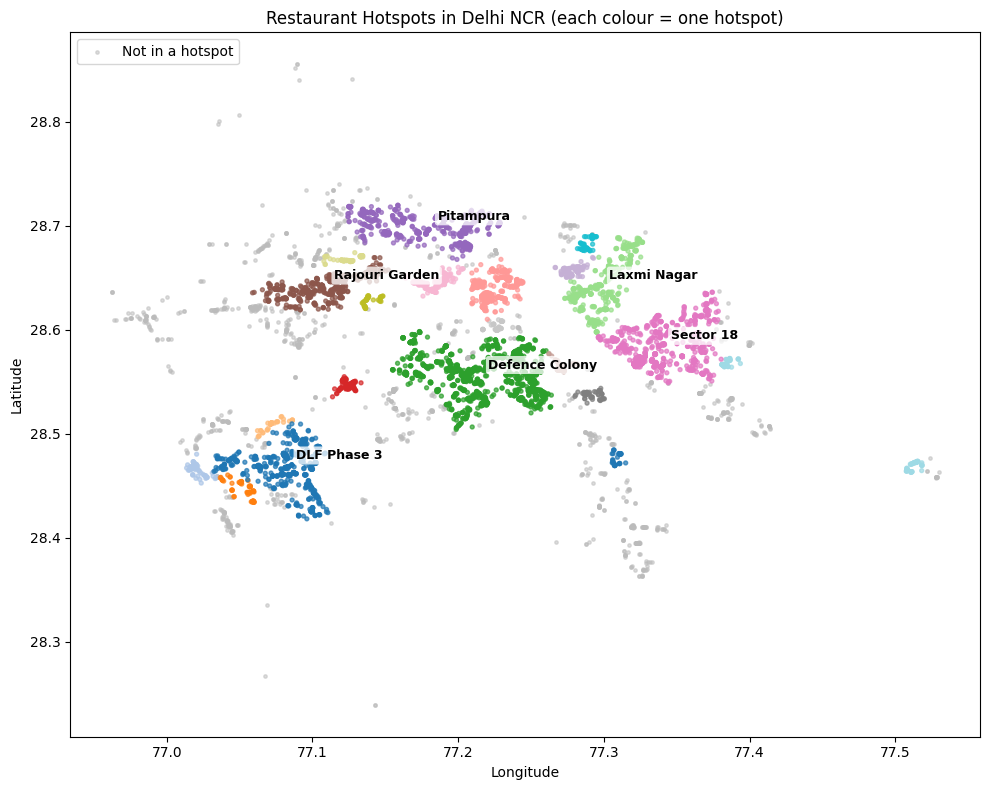

In [19]:
plt.figure(figsize=(10, 8))
outside = ncr[ncr["Hotspot"] == -1]
inside = ncr[ncr["Hotspot"] >= 0]

plt.scatter(outside["Longitude"], outside["Latitude"], s=6, color="#BBBBBB", alpha=0.5, label="Not in a hotspot")
plt.scatter(inside["Longitude"], inside["Latitude"], s=8, c=inside["Hotspot"], cmap="tab20", alpha=0.7)

for _, row in hotspots.head(6).iterrows():
    plt.annotate(row["Main_Locality"], (row["Avg_Longitude"], row["Avg_Latitude"]),
                 fontsize=9, fontweight="bold", xytext=(5, 5), textcoords="offset points",
                 bbox=dict(boxstyle="round,pad=0.2", fc="white", alpha=0.75, lw=0))

plt.title("Restaurant Hotspots in Delhi NCR (each colour = one hotspot)")
plt.xlabel("Longitude")
plt.ylabel("Latitude")
plt.legend(loc="upper left")
plt.tight_layout()
plt.show()

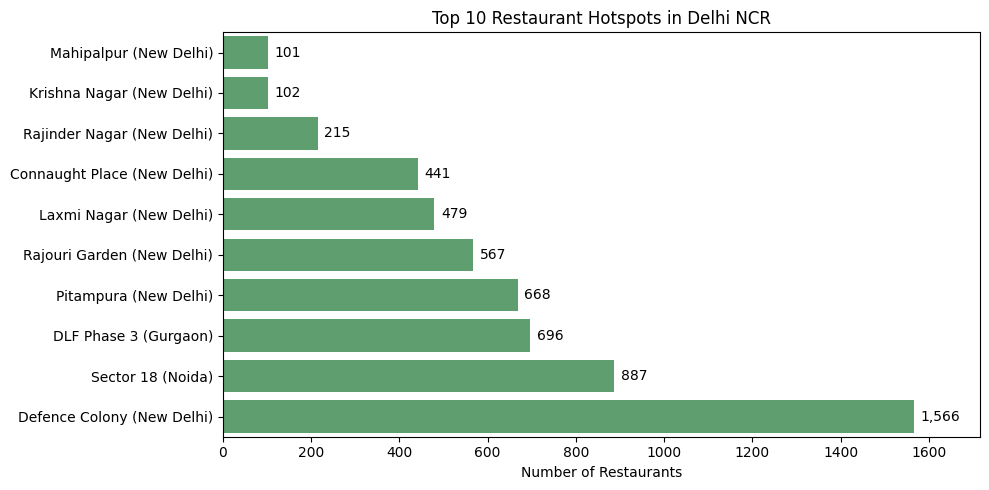

In [20]:
top_h = hotspots.head(10).copy()
top_h["Label"] = top_h["Main_Locality"] + " (" + top_h["City"] + ")"
top_h = top_h.sort_values("Restaurants")

plt.figure(figsize=(10, 5))
ax = sns.barplot(x=top_h["Restaurants"], y=top_h["Label"], color="#55A868")
for i, v in enumerate(top_h["Restaurants"]):
    ax.text(v + 15, i, f"{v:,}", va="center")
plt.xlim(0, top_h["Restaurants"].max() + 150)
plt.title("Top 10 Restaurant Hotspots in Delhi NCR")
plt.xlabel("Number of Restaurants")
plt.ylabel("")
plt.tight_layout()
plt.show()

## 6. Do Hotspots Differ in Rating?

In [21]:
ncr_avg = rated_ncr["Aggregate rating"].mean()
in_avg = rated_ncr[rated_ncr["Hotspot"] >= 0]["Aggregate rating"].mean()
out_avg = rated_ncr[rated_ncr["Hotspot"] == -1]["Aggregate rating"].mean()
print(f"Average rating, whole NCR (rated only):   {ncr_avg:.2f}")
print(f"Average rating, inside hotspots:          {in_avg:.2f}")
print(f"Average rating, outside hotspots:         {out_avg:.2f}")

rating_rank = hotspots.sort_values("Avg Rating (rated only)", ascending=False)
rating_rank[["Main_Locality", "City", "Restaurants", "Avg Rating (rated only)"]]

Average rating, whole NCR (rated only):   3.28
Average rating, inside hotspots:          3.29
Average rating, outside hotspots:         3.19


,Main_Locality,City,Restaurants,Avg Rating (rated only)
Hotspot,,,,
16,Khan Market,New Delhi,73,3.78
8,Connaught Place,New Delhi,441,3.49
1,DLF Phase 3,Gurgaon,696,3.40
18,Punjabi Bagh,New Delhi,66,3.37
5,Defence Colony,New Delhi,1566,3.37
9,Pitampura,New Delhi,668,3.29
11,Rajouri Garden,New Delhi,567,3.25
4,"Unitech Infospace, Sector 21, Gurgaon",Gurgaon,54,3.20
14,Rajinder Nagar,New Delhi,215,3.18


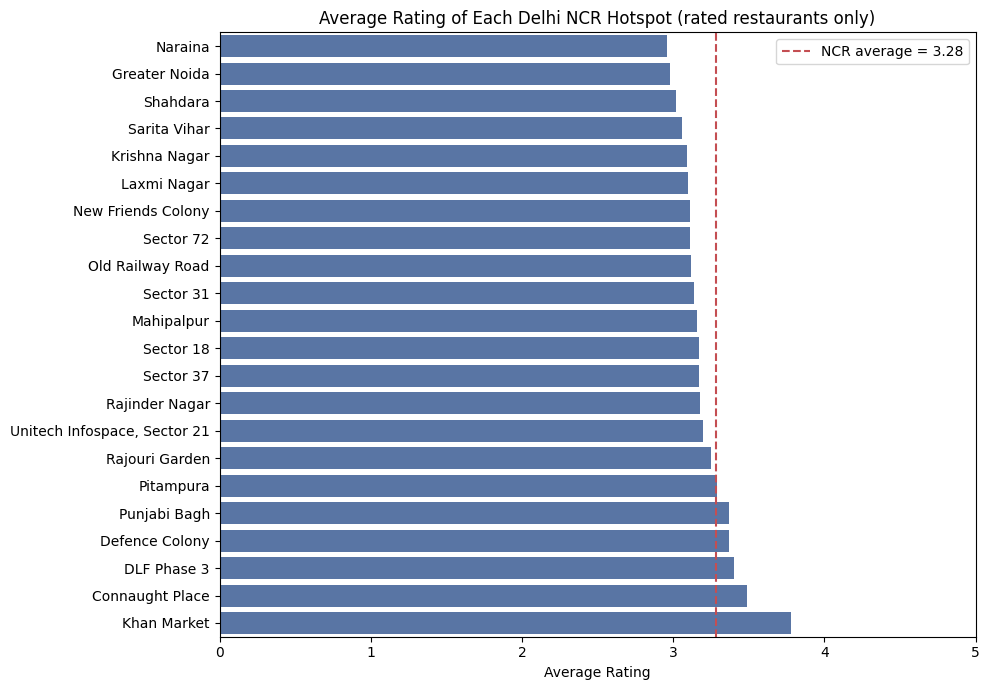

In [22]:
plot_rank = rating_rank.sort_values("Avg Rating (rated only)")

plt.figure(figsize=(10, 7))
sns.barplot(x=plot_rank["Avg Rating (rated only)"], y=plot_rank["Main_Locality"].str.slice(0, 28), color="#4C72B0")
plt.axvline(ncr_avg, color="#C44E52", linestyle="--", label=f"NCR average = {ncr_avg:.2f}")
plt.xlim(0, 5)
plt.title("Average Rating of Each Delhi NCR Hotspot (rated restaurants only)")
plt.xlabel("Average Rating")
plt.ylabel("")
plt.legend()
plt.tight_layout()
plt.show()

## 7. Interactive Map 

In [23]:
try:
    import folium
    from folium.plugins import FastMarkerCluster

    m = folium.Map(location=[28.6, 77.2], zoom_start=5)
    FastMarkerCluster(geo[["Latitude", "Longitude"]].values.tolist()).add_to(m)
    m.save("restaurant_map.html")
    print("Saved restaurant_map.html in this folder. Open it in a browser and zoom in to explore.")
except ImportError:
    print("folium is not installed. Run: pip install folium")

Saved restaurant_map.html in this folder. Open it in a browser and zoom in to explore.


## 8. Final Results

In [24]:
task_result = pd.DataFrame({
    "Question": [
        "Restaurants with valid coordinates",
        "Countries covered",
        "Share of valid restaurants in India",
        "Restaurants in the Delhi NCR area",
        "Clusters across the whole dataset",
        "Largest cluster",
        "Hotspots found inside Delhi NCR",
        "Share of NCR restaurants inside hotspots",
    ],
    "Answer": [
        f"{len(geo):,} ({len(geo) / len(df) * 100:.2f}% of all listings)",
        country_table.shape[0],
        f"{country_table.loc[0, 'Percentage']:.2f}%",
        f"{len(ncr):,} ({len(ncr) / len(geo) * 100:.2f}% of valid)",
        n_clusters,
        f"{clusters.iloc[0]['Restaurants']:,.0f} restaurants around {clusters.iloc[0]['Main_City']}",
        n_hot,
        f"{hotspots['Restaurants'].sum() / len(ncr) * 100:.2f}%",
    ],
})
task_result

,Question,Answer
0,Restaurants with valid coordinates,"9,051 (94.76% of all listings)"
1,Countries covered,15
2,Share of valid restaurants in India,90.10%
3,Restaurants in the Delhi NCR area,"7,549 (83.41% of valid)"
4,Clusters across the whole dataset,26
5,Largest cluster,"7,483 restaurants around New Delhi"
6,Hotspots found inside Delhi NCR,22
7,Share of NCR restaurants inside hotspots,84.94%


## 9. Validation

In [25]:
print("Valid + zero-coordinate + out-of-place = total:", len(geo) + zero_coords.sum() + far.sum() == len(df))
print("Country counts add up to valid restaurants:", country_table["Restaurants"].sum() == len(geo))
print("Hotspot + outside-hotspot = NCR total:", hotspots["Restaurants"].sum() + n_outside == len(ncr))

Valid + zero-coordinate + out-of-place = total: True
Country counts add up to valid restaurants: True
Hotspot + outside-hotspot = NCR total: True


### Business Insights

**Data quality**

- **5.22% of listings (499) have a placeholder coordinate of 0** and one more
  is a test record ("Test Restaruants for Medio") placed thousands of km from
  its city. After removing them, **9,051 restaurants (94.76%)** are mapped. Most
  invalid coordinates are in New Delhi (233), Noida (94) and Gurgaon (48).

**Where the restaurants are**

- **The data covers 15 countries, but it is overwhelmingly Indian.** India has
  8,155 of the 9,051 mapped restaurants (90.10%), followed by the United States
  (434, 4.80%) and the United Kingdom (80, 0.88%). Most other countries have
  only 20 to 60 restaurants.
- **Delhi NCR dominates.** 7,549 restaurants (83.41% of the mapped ones) lie in
  the NCR: New Delhi 5,239, Gurgaon 1,070, Noida 986, Faridabad 229 and
  Ghaziabad 25.
- **The NCR forms one continuous urban cluster.** At a 10 km scale, DBSCAN joins
  New Delhi, Gurgaon, Noida, Faridabad and Ghaziabad into a single cluster of
  7,483 restaurants (82.68%). The other 25 clusters are small, and 23 of them
  have only 20 to 25 restaurants.
- **Outside the NCR, clusters mostly reflect how the data was collected.** 131
  of 141 cities have 20 or fewer listings, so a "cluster" of exactly 20 simply
  shows a city that was sampled, not a busy restaurant area.

**Hotspots inside Delhi NCR**

- **Restaurants are concentrated in a few dense areas.** At a 1 km scale, 22
  hotspots hold 6,412 of the 7,549 NCR restaurants (84.94%). The three largest
  hold 41.71% of the NCR, and the largest one (named after Defence Colony,
  spreading across South Delhi) alone holds 20.74%.
- **The biggest hotspots** are Defence Colony (1,566), Sector 18 in Noida (887),
  DLF Phase 3 in Gurgaon (696), Pitampura (668), Rajouri Garden (567), Laxmi
  Nagar (479) and Connaught Place (441).

**Ratings by location**

- **Being in a hotspot makes only a small difference to rating.** Rated
  restaurants average 3.29 inside hotspots versus 3.19 outside them.
- **Central, upscale areas rate highest.** Khan Market (3.78), Connaught Place
  (3.49) and DLF Phase 3 (3.40) lead, while Naraina (2.96), Greater Noida
  (2.98) and Shahdara (3.02) are lowest. Rating therefore varies more between
  neighbourhoods than between "dense" and "not dense" areas.

**Caution**

- Hotspots are named after their most common locality, but each can cover
  several localities because DBSCAN links neighbouring dense areas.
- Some hotspots have only about 20 to 30 rated restaurants, so their average
  ratings are indicative, not definitive.
- The cluster results depend on the chosen settings (10 km and 20 restaurants
  worldwide, 1 km and 40 restaurants in the NCR). Different settings would give
  different clusters.
- 2,148 unrated restaurants (rating 0) are excluded from all rating averages.
- The patterns describe where restaurants are listed in this dataset, not
  necessarily where the most restaurants exist in reality.